# Notebook 2 · Implementación básica de un Transformer para series de tiempo

**Especialización en Inteligencia Artificial – Universidad de Cundinamarca**
**Asignatura:** Deep Learning – Conceptos (604013) · **Actividad:** R2-A3-S12 Transformers

En el notebook anterior le agregué atención a una red recurrente. Aquí doy el paso que propone *Attention Is All You Need*: **quitar la recurrencia por completo** y construir el modelo solo con atención.

Implementé desde cero, con TensorFlow + Keras, las piezas del *encoder* del Transformer:

- Atención por producto punto escalado (*scaled dot-product attention*).
- Atención multi-cabeza (*multi-head self-attention*).
- Codificación posicional sinusoidal.
- Bloque encoder con conexiones residuales, normalización de capa y red *feed-forward*.

Como el problema es predecir un solo valor (la temperatura mínima de mañana), no hace falta el *decoder*: basta con un encoder y una capa de salida. Uso la misma serie, la misma ventana de 30 días y la misma división temporal del notebook 1, para poder comparar en igualdad de condiciones.

## 1. Librerías y configuración

In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers, ops
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

keras.utils.set_random_seed(42)
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

I0000 00:00:1795219031.024286    2377 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795219032.240619    2377 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | Keras: 3.15.1


## 2. La pieza base: atención por producto punto escalado

Antes de armar el modelo quise ver la fórmula funcionando con números pequeños:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

La intuición que me sirvió es pensarlo como una búsqueda: cada posición lanza una **consulta** ($Q$), la compara con las **claves** ($K$) de todas las posiciones y recoge una mezcla de sus **valores** ($V$) según qué tan parecidas resultaron. La división por $\sqrt{d_k}$ evita que los productos punto crezcan demasiado y que el softmax se sature.

In [2]:
def atencion_producto_punto(Q, K, V, mascara=None):
    d_k = ops.cast(ops.shape(K)[-1], "float32")
    puntajes = ops.matmul(Q, ops.swapaxes(K, -1, -2)) / ops.sqrt(d_k)
    if mascara is not None:
        puntajes = puntajes + (1.0 - mascara) * -1e9
    pesos = ops.softmax(puntajes, axis=-1)
    return ops.matmul(pesos, V), pesos

# Ejemplo de juguete: 3 posiciones con vectores de dimensión 4
Q = K = V = np.array([[1, 0, 1, 0],
                      [0, 1, 0, 1],
                      [1, 1, 0, 0]], dtype="float32")[None]
salida, pesos = atencion_producto_punto(Q, K, V)
print("Pesos de atención (cada fila suma 1):\n", np.round(np.asarray(pesos)[0], 3))
print("\nSalida:\n", np.round(np.asarray(salida)[0], 3))

Pesos de atención (cada fila suma 1):
 [[0.506 0.186 0.307]
 [0.186 0.506 0.307]
 [0.274 0.274 0.452]]

Salida:
 [[0.814 0.494 0.506 0.186]
 [0.494 0.814 0.186 0.506]
 [0.726 0.726 0.274 0.274]]


Se ve que cada posición se atiende más a sí misma y a las posiciones con las que comparte componentes, que es justo lo que se espera de la auto-atención.

## 3. Datos y preprocesamiento

Repito el mismo tratamiento del notebook 1: división temporal (1981–1987 entrenamiento, 1988 validación, 1989–1990 prueba), estandarización con la media y la desviación del entrenamiento y ventanas de 30 días.

In [3]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv"
df = pd.read_csv(URL, parse_dates=["Date"], index_col="Date")
df.columns = ["temp"]

VENTANA = 30
serie = df["temp"].values.astype("float32")
fechas = df.index
train_end = fechas <= "1987-12-31"
media, desv = serie[train_end].mean(), serie[train_end].std()
serie_esc = (serie - media) / desv

def crear_ventanas(x, ventana):
    X, y = [], []
    for i in range(len(x) - ventana):
        X.append(x[i:i + ventana]); y.append(x[i + ventana])
    return np.array(X)[..., None], np.array(y)

X, y = crear_ventanas(serie_esc, VENTANA)
fechas_y = fechas[VENTANA:]
m_train = fechas_y <= "1987-12-31"
m_val = (fechas_y > "1987-12-31") & (fechas_y <= "1988-12-31")
m_test = fechas_y > "1988-12-31"
X_train, y_train = X[m_train], y[m_train]
X_val, y_val = X[m_val], y[m_val]
X_test, y_test = X[m_test], y[m_test]
print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)

def desescalar(z):
    return np.asarray(z).ravel() * desv + media

def metricas(y_real, y_pred):
    return {"MAE": float(mean_absolute_error(y_real, y_pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
            "R2": float(r2_score(y_real, y_pred))}

y_test_c = desescalar(y_test)
res_base = metricas(y_test_c, desescalar(X_test[:, -1, 0]))
print("Persistencia →", {k: round(v, 3) for k, v in res_base.items()})

X_train: (2525, 30, 1) | X_val: (365, 30, 1) | X_test: (730, 30, 1)
Persistencia → {'MAE': 1.953, 'RMSE': 2.481, 'R2': 0.635}


## 4. Codificación posicional

Como la auto-atención procesa todas las posiciones en paralelo, por sí sola **no sabe en qué orden vienen los datos**: para ella, la ventana sería un conjunto desordenado de días. La codificación posicional le suma a cada posición un patrón único de senos y cosenos:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d}}\right) \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

Las primeras dimensiones oscilan rápido y las últimas despacio, algo así como las manecillas de un reloj que marcan segundos, minutos y horas.

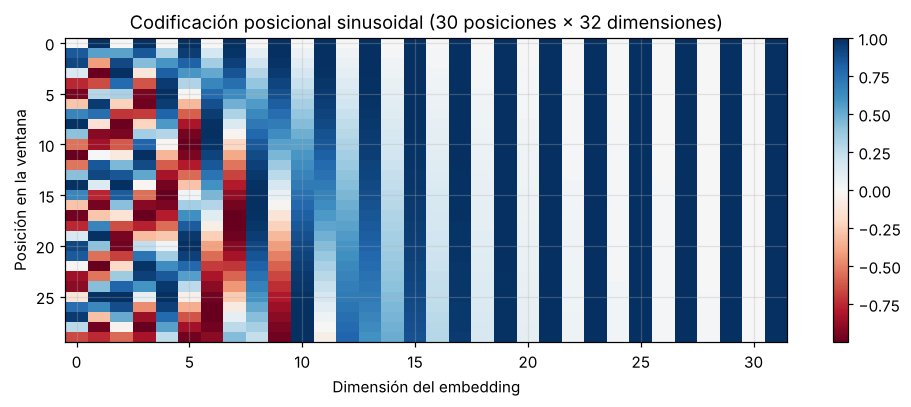

In [4]:
def codificacion_posicional(longitud, d_model):
    pos = np.arange(longitud)[:, None]
    i = np.arange(d_model)[None, :]
    angulos = pos / np.power(10000, (2 * (i // 2)) / d_model)
    pe = np.zeros((longitud, d_model), dtype="float32")
    pe[:, 0::2] = np.sin(angulos[:, 0::2])
    pe[:, 1::2] = np.cos(angulos[:, 1::2])
    return pe

D_MODEL = 32
pe = codificacion_posicional(VENTANA, D_MODEL)
plt.figure(figsize=(9, 3.8))
plt.imshow(pe, aspect="auto", cmap="RdBu")
plt.colorbar(); plt.xlabel("Dimensión del embedding"); plt.ylabel("Posición en la ventana")
plt.title("Codificación posicional sinusoidal (30 posiciones × 32 dimensiones)")
plt.tight_layout(); plt.savefig("figuras/nb2_codificacion_posicional.png", bbox_inches="tight"); plt.show()

## 5. Componentes del Transformer

### 5.1 Atención multi-cabeza
En lugar de una sola atención, el modelo calcula varias en paralelo (*cabezas*), cada una con sus propias proyecciones de $Q$, $K$ y $V$. Así cada cabeza puede especializarse en un tipo de relación distinta (por ejemplo, días recientes vs. días extremos). Al final se concatenan y se proyectan de nuevo.

In [5]:
class AtencionMultiCabeza(layers.Layer):
    def __init__(self, d_model, num_cabezas, **kwargs):
        super().__init__(**kwargs)
        assert d_model % num_cabezas == 0
        self.h, self.d_k = num_cabezas, d_model // num_cabezas
        self.wq, self.wk, self.wv = layers.Dense(d_model), layers.Dense(d_model), layers.Dense(d_model)
        self.wo = layers.Dense(d_model)

    def separar_cabezas(self, x):
        # (batch, T, d_model) -> (batch, h, T, d_k)
        b, t = ops.shape(x)[0], ops.shape(x)[1]
        x = ops.reshape(x, (b, t, self.h, self.d_k))
        return ops.transpose(x, (0, 2, 1, 3))

    def call(self, x):
        Q = self.separar_cabezas(self.wq(x))
        K = self.separar_cabezas(self.wk(x))
        V = self.separar_cabezas(self.wv(x))
        salida, pesos = atencion_producto_punto(Q, K, V)        # (batch, h, T, d_k)
        salida = ops.transpose(salida, (0, 2, 1, 3))
        b, t = ops.shape(salida)[0], ops.shape(salida)[1]
        salida = ops.reshape(salida, (b, t, self.h * self.d_k))  # concatenar cabezas
        return self.wo(salida), pesos

### 5.2 Bloque encoder
Cada bloque tiene dos subcapas: la atención multi-cabeza y una red *feed-forward* que se aplica a cada posición por separado. Ambas van envueltas en una **conexión residual** seguida de **normalización de capa** (*Add & Norm*), igual que en la Figura 1 del paper. Las conexiones residuales ayudan a que el gradiente fluya y la normalización estabiliza el entrenamiento.

In [6]:
class BloqueEncoder(layers.Layer):
    def __init__(self, d_model, num_cabezas, d_ff, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.mha = AtencionMultiCabeza(d_model, num_cabezas)
        self.ffn = keras.Sequential([layers.Dense(d_ff, activation="relu"), layers.Dense(d_model)])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1 = layers.Dropout(dropout)
        self.drop2 = layers.Dropout(dropout)

    def call(self, x, training=False):
        att, pesos = self.mha(x)
        x = self.norm1(x + self.drop1(att, training=training))      # Add & Norm 1
        ff = self.ffn(x)
        x = self.norm2(x + self.drop2(ff, training=training))       # Add & Norm 2
        return x, pesos


class SumarPosicion(layers.Layer):
    def __init__(self, longitud, d_model, **kwargs):
        super().__init__(**kwargs)
        self.pe = ops.convert_to_tensor(codificacion_posicional(longitud, d_model))[None]

    def call(self, x):
        return x + self.pe

### 5.3 Modelo completo

1. **Embedding de entrada:** cada temperatura (un escalar) se proyecta a un vector de 32 dimensiones con una capa densa, que hace el papel de los *embeddings* de palabras en NLP.
2. **Codificación posicional** sumada al embedding.
3. **Dos bloques encoder** con 4 cabezas de atención y una *feed-forward* de 64 unidades.
4. **Cabeza de predicción:** combino la representación del último día con el promedio de toda la secuencia y lo paso por capas densas hasta una única salida.

También armo una variante **sin codificación posicional**, para comprobar en la práctica qué tanto importa esa pieza.

In [7]:
def construir_transformer(d_model=32, num_cabezas=4, d_ff=64, num_bloques=2, dropout=0.1, usar_pe=True):
    entrada = keras.Input(shape=(VENTANA, 1))
    x = layers.Dense(d_model, name="embedding")(entrada)
    if usar_pe:
        x = SumarPosicion(VENTANA, d_model, name="codificacion_posicional")(x)
    x = layers.Dropout(dropout)(x)
    todos_pesos = []
    for b in range(num_bloques):
        x, pesos = BloqueEncoder(d_model, num_cabezas, d_ff, dropout, name=f"encoder_{b+1}")(x)
        todos_pesos.append(pesos)
    ultimo = x[:, -1, :]
    promedio = layers.GlobalAveragePooling1D()(x)
    z = layers.Concatenate()([ultimo, promedio])
    z = layers.Dense(32, activation="relu")(z)
    z = layers.Dropout(dropout)(z)
    salida = layers.Dense(1)(z)
    nombre = "Transformer" if usar_pe else "Transformer_sin_PE"
    modelo = keras.Model(entrada, salida, name=nombre)
    modelo_pesos = keras.Model(entrada, todos_pesos, name=nombre + "_pesos")
    return modelo, modelo_pesos

transformer, transformer_pesos = construir_transformer()
transformer.summary()

Model: "Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding (Dense)   │ (None, 30, 32)    │         64 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ codificacion_posic… │ (None, 30, 32)    │          0 │ embedding[0][0]   │
│ (SumarPosicion)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 30, 32)    │          0 │ codificacion_pos… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_1           │ [(None, 30, 32),  │      8,544 │ dropout[0][0]     │
│ (BloqueEncoder)     │ (None, 4, 30,     │            │                   │
│                     │ 30)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_2           │ [(None, 30, 32),  │      8,544 │ encoder_1[0][0]   │
│ (BloqueEncoder)     │ (None, 4, 30,     │            │                   │
│                     │ 30)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 32)        │          0 │ encoder_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ encoder_2[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64)        │          0 │ get_item[0][0],   │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 32)        │      2,080 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 32)        │          0 │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 1)         │         33 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,265 (75.25 KB)

 Trainable params: 19,265 (75.25 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento

Mismas condiciones que en el notebook 1 (Adam, MSE, lotes de 32, *early stopping* con paciencia de 10). Bajé un poco la tasa de aprendizaje a 5·10⁻⁴ porque los Transformers suelen ser algo más sensibles a este hiperparámetro.

In [8]:
def entrenar(modelo, epocas=80):
    modelo.compile(optimizer=keras.optimizers.Adam(5e-4), loss="mse", metrics=["mae"])
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    return modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=epocas, batch_size=32, callbacks=[parada], verbose=2)

print("=== Transformer ===")
hist_tf = entrenar(transformer)

=== Transformer ===
Epoch 1/80


79/79 - 6s - 73ms/step - loss: 0.6171 - mae: 0.6116 - val_loss: 0.3684 - val_mae: 0.4684


Epoch 2/80


79/79 - 1s - 12ms/step - loss: 0.4547 - mae: 0.5299 - val_loss: 0.3628 - val_mae: 0.4699


Epoch 3/80


79/79 - 1s - 13ms/step - loss: 0.4342 - mae: 0.5148 - val_loss: 0.3641 - val_mae: 0.4727


... (62 outputs left out)

Epoch 35/80


79/79 - 1s - 17ms/step - loss: 0.3730 - mae: 0.4758 - val_loss: 0.3391 - val_mae: 0.4543


Epoch 36/80


79/79 - 1s - 13ms/step - loss: 0.3720 - mae: 0.4784 - val_loss: 0.3424 - val_mae: 0.4563


In [9]:
keras.utils.set_random_seed(42)
transformer_sin_pe, _ = construir_transformer(usar_pe=False)
print("=== Transformer sin codificación posicional ===")
hist_sin_pe = entrenar(transformer_sin_pe)

=== Transformer sin codificación posicional ===
Epoch 1/80


79/79 - 6s - 70ms/step - loss: 0.6339 - mae: 0.6176 - val_loss: 0.3842 - val_mae: 0.4880


Epoch 2/80


79/79 - 1s - 14ms/step - loss: 0.4669 - mae: 0.5386 - val_loss: 0.3734 - val_mae: 0.4775


Epoch 3/80


79/79 - 1s - 16ms/step - loss: 0.4331 - mae: 0.5116 - val_loss: 0.3611 - val_mae: 0.4710


... (26 outputs left out)

Epoch 17/80


79/79 - 1s - 16ms/step - loss: 0.3811 - mae: 0.4858 - val_loss: 0.3659 - val_mae: 0.4646


Epoch 18/80


79/79 - 1s - 14ms/step - loss: 0.3881 - mae: 0.4867 - val_loss: 0.3595 - val_mae: 0.4608


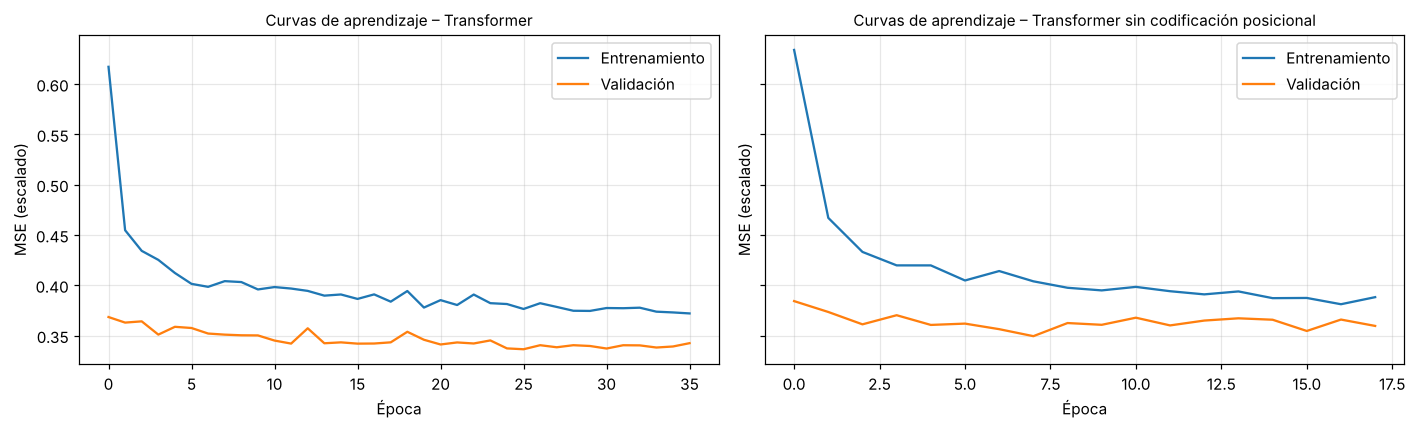

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, h, nombre in zip(axes, [hist_tf, hist_sin_pe], ["Transformer", "Transformer sin codificación posicional"]):
    ax.plot(h.history["loss"], label="Entrenamiento")
    ax.plot(h.history["val_loss"], label="Validación")
    ax.set_title(f"Curvas de aprendizaje – {nombre}", fontsize=10)
    ax.set_xlabel("Época"); ax.set_ylabel("MSE (escalado)"); ax.legend()
plt.tight_layout(); plt.savefig("figuras/nb2_curvas.png", bbox_inches="tight"); plt.show()

## 7. Evaluación en el conjunto de prueba (1989–1990)

In [11]:
pred_tf = desescalar(transformer.predict(X_test, verbose=0))
pred_sin_pe = desescalar(transformer_sin_pe.predict(X_test, verbose=0))

tabla = {"Persistencia (base)": res_base,
         "Transformer sin codificación posicional": metricas(y_test_c, pred_sin_pe),
         "Transformer": metricas(y_test_c, pred_tf)}

# Si el notebook 1 se ejecutó en el mismo entorno, traigo sus resultados para comparar
if os.path.exists("resultados/nb1_metricas.json"):
    with open("resultados/nb1_metricas.json", encoding="utf-8") as f:
        nb1 = json.load(f)["metricas_test"]
    tabla["LSTM sin atención (nb1)"] = nb1["LSTM sin atención"]
    tabla["LSTM con atención (nb1)"] = nb1["LSTM con atención"]

resultados = pd.DataFrame(tabla).T.round(3).sort_values("MAE")
resultados

,MAE,RMSE,R2
LSTM sin atención (nb1),1.712,2.176,0.719
LSTM con atención (nb1),1.712,2.175,0.719
Transformer,1.716,2.196,0.714
Transformer sin codificación posicional,1.779,2.285,0.690
Persistencia (base),1.953,2.481,0.635


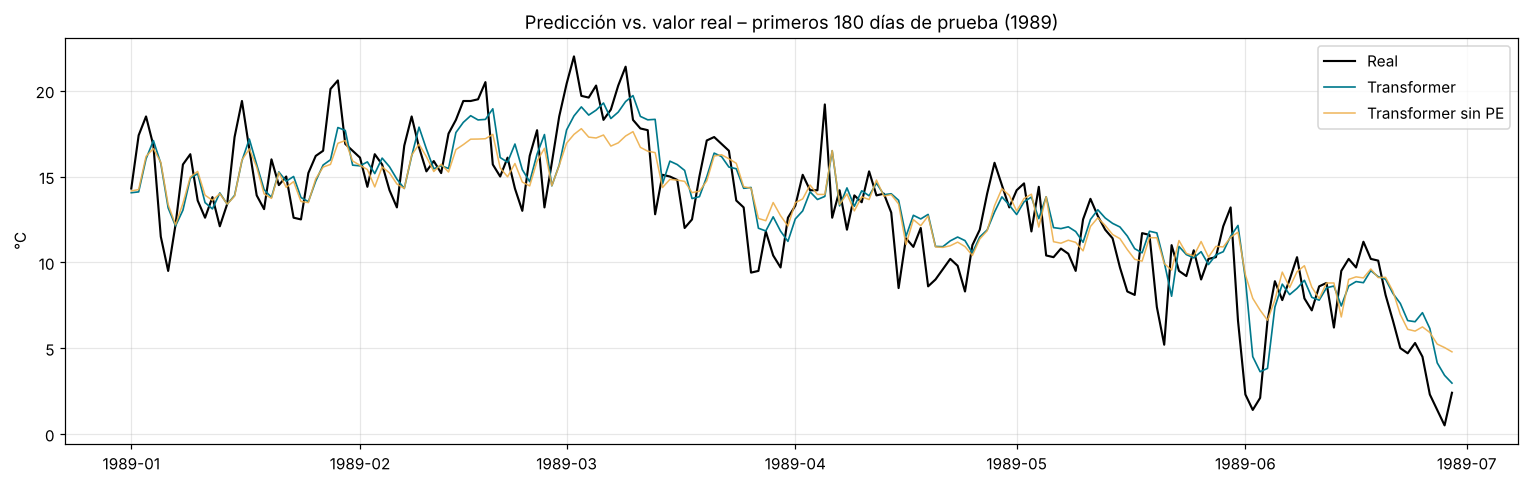

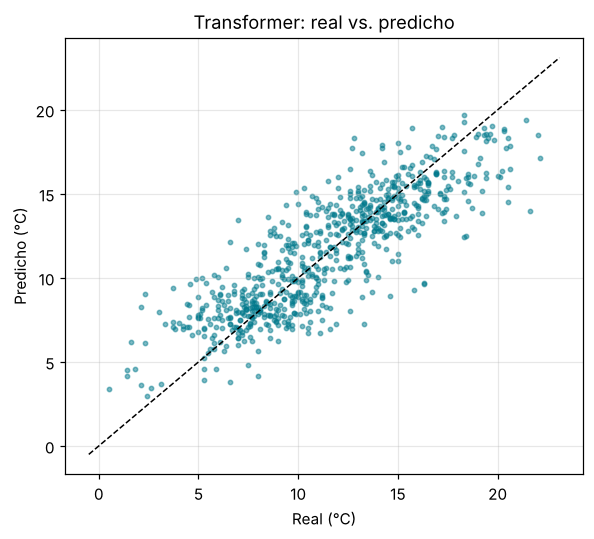

In [12]:
idx = slice(0, 180)
f_test = fechas_y[m_test]
plt.figure(figsize=(14, 4.5))
plt.plot(f_test[idx], y_test_c[idx], color="black", lw=1.4, label="Real")
plt.plot(f_test[idx], pred_tf[idx], color="#00798c", lw=1.1, label="Transformer")
plt.plot(f_test[idx], pred_sin_pe[idx], color="#edae49", lw=1.0, alpha=0.9, label="Transformer sin PE")
plt.title("Predicción vs. valor real – primeros 180 días de prueba (1989)")
plt.ylabel("°C"); plt.legend()
plt.tight_layout(); plt.savefig("figuras/nb2_predicciones.png", bbox_inches="tight"); plt.show()

plt.figure(figsize=(5.5, 5))
plt.scatter(y_test_c, pred_tf, s=8, alpha=0.5, color="#00798c")
lim = [y_test_c.min() - 1, y_test_c.max() + 1]
plt.plot(lim, lim, "k--", lw=1)
plt.xlabel("Real (°C)"); plt.ylabel("Predicho (°C)"); plt.title("Transformer: real vs. predicho")
plt.tight_layout(); plt.savefig("figuras/nb2_dispersion.png", bbox_inches="tight"); plt.show()

## 8. Mapas de auto-atención

Cada bloque devuelve una matriz de atención por cabeza de tamaño 30 × 30: la fila es el día que "pregunta" y la columna el día al que mira. Visualizo las 4 cabezas del último bloque para una ventana de prueba y, además, el promedio sobre todo el conjunto de prueba de lo que mira la **última posición** (que es la que más pesa en la predicción).

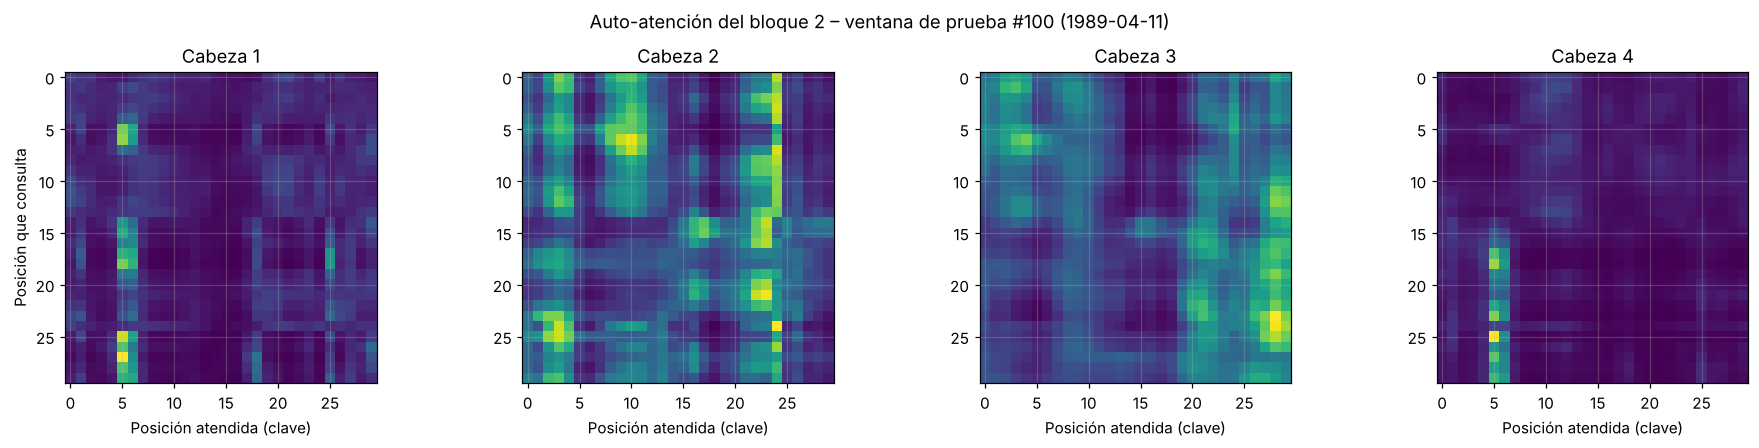

In [13]:
pesos_bloques = transformer_pesos.predict(X_test, verbose=0)
pesos_ultimo = np.asarray(pesos_bloques[-1])           # (n, cabezas, 30, 30)
i = 100

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for c in range(4):
    im = axes[c].imshow(pesos_ultimo[i, c], cmap="viridis")
    axes[c].set_title(f"Cabeza {c+1}"); axes[c].set_xlabel("Posición atendida (clave)")
    if c == 0: axes[c].set_ylabel("Posición que consulta")
plt.suptitle(f"Auto-atención del bloque 2 – ventana de prueba #{i} ({f_test[i].date()})")
plt.tight_layout(); plt.savefig("figuras/nb2_mapas_atencion.png", bbox_inches="tight"); plt.show()

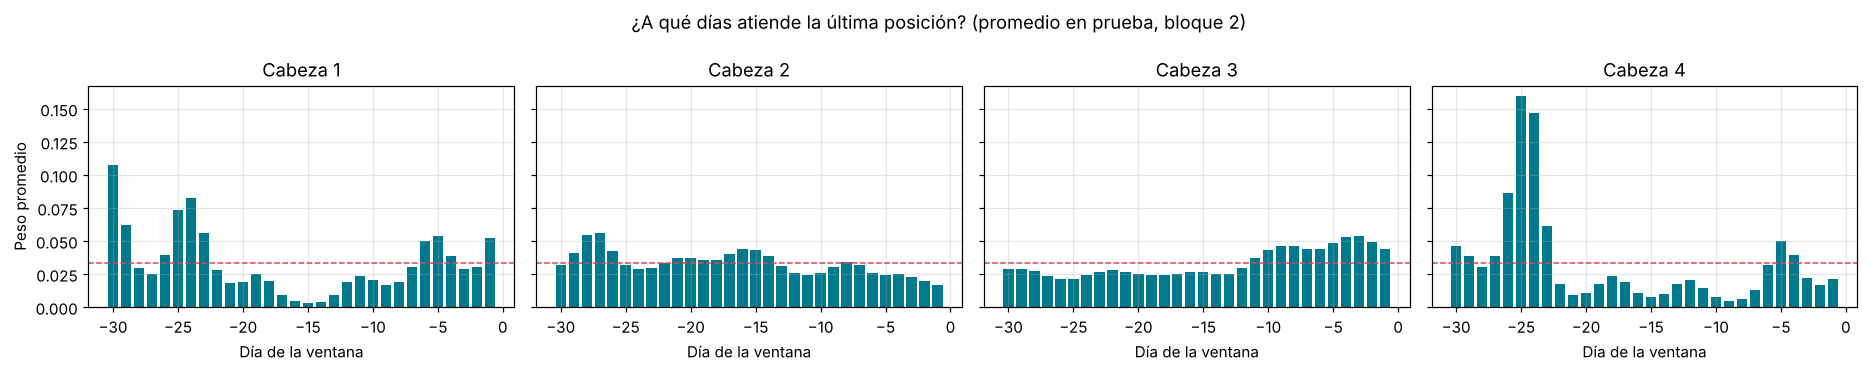

Cabeza 1: peso en los últimos 5 días = 20.4% | correlación con la temperatura = -0.459
Cabeza 2: peso en los últimos 5 días = 10.8% | correlación con la temperatura = +0.545
Cabeza 3: peso en los últimos 5 días = 24.8% | correlación con la temperatura = -0.246
Cabeza 4: peso en los últimos 5 días = 15.0% | correlación con la temperatura = -0.192


In [14]:
desfases = np.arange(-VENTANA, 0)
ultima_fila = pesos_ultimo[:, :, -1, :]                 # lo que mira el último día, por cabeza
fig, axes = plt.subplots(1, 4, figsize=(17, 3.4), sharey=True)
for c in range(4):
    axes[c].bar(desfases, ultima_fila[:, c, :].mean(axis=0), color="#00798c")
    axes[c].axhline(1 / VENTANA, color="#d1495b", ls="--", lw=1)
    axes[c].set_title(f"Cabeza {c+1}"); axes[c].set_xlabel("Día de la ventana")
axes[0].set_ylabel("Peso promedio")
plt.suptitle("¿A qué días atiende la última posición? (promedio en prueba, bloque 2)")
plt.tight_layout(); plt.savefig("figuras/nb2_atencion_ultima_posicion.png", bbox_inches="tight"); plt.show()

x_test_c = X_test[:, :, 0] * desv + media
for c in range(4):
    w = ultima_fila[:, c, :]
    corr = np.mean([np.corrcoef(w[k], x_test_c[k])[0, 1] for k in range(len(w))])
    reciente = w[:, -5:].sum(axis=1).mean()
    print(f"Cabeza {c+1}: peso en los últimos 5 días = {reciente:.1%} | correlación con la temperatura = {corr:+.3f}")

In [15]:
x_test_c = X_test[:, :, 0] * desv + media
resumen_cabezas = []
for c in range(4):
    w = ultima_fila[:, c, :]
    resumen_cabezas.append({
        "cabeza": c + 1,
        "peso_ultimos_5": float(w[:, -5:].sum(axis=1).mean()),
        "corr_temp": float(np.mean([np.corrcoef(w[k], x_test_c[k])[0, 1] for k in range(len(w))])),
    })

salida = {
    "metricas_test": resultados.to_dict(orient="index"),
    "epocas": {"Transformer": len(hist_tf.history["loss"]),
               "Transformer sin PE": len(hist_sin_pe.history["loss"])},
    "parametros": {"Transformer": int(transformer.count_params())},
    "cabezas": resumen_cabezas,
}
with open("resultados/nb2_metricas.json", "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False, indent=2)
print(json.dumps(salida, indent=2, ensure_ascii=False))

{
  "metricas_test": {
    "LSTM sin atención (nb1)": {
      "MAE": 1.712,
      "RMSE": 2.176,
      "R2": 0.719
    },
    "LSTM con atención (nb1)": {
      "MAE": 1.712,
      "RMSE": 2.175,
      "R2": 0.719
    },
    "Transformer": {
      "MAE": 1.716,
      "RMSE": 2.196,
      "R2": 0.714
    },
    "Transformer sin codificación posicional": {
      "MAE": 1.779,
      "RMSE": 2.285,
      "R2": 0.69
    },
    "Persistencia (base)": {
      "MAE": 1.953,
      "RMSE": 2.481,
      "R2": 0.635
    }
  },
  "epocas": {
    "Transformer": 36,
    "Transformer sin PE": 18
  },
  "parametros": {
    "Transformer": 19265
  },
  "cabezas": [
    {
      "cabeza": 1,
      "peso_ultimos_5": 0.2039586901664734,
      "corr_temp": -0.45852679966437065
    },
    {
      "cabeza": 2,
      "peso_ultimos_5": 0.10845475643873215,
      "corr_temp": 0.5447040422727143
    },
    {
      "cabeza": 3,
      "peso_ultimos_5": 0.24845601618289948,
      "corr_temp": -0.24648662315004946
    

## 9. Conclusiones

- **El Transformer funciona sin una sola capa recurrente.** Con unos 19 mil parámetros y dos bloques encoder, logró un MAE de 1,72 °C y un R² de 0,71 en prueba, muy por encima de la persistencia (1,95 °C) y prácticamente al nivel de las LSTM del notebook 1 (1,71 °C). Para una serie corta y univariada como esta, era de esperarse que no hubiera una ventaja grande. La fortaleza del Transformer aparece más en secuencias largas y en conjuntos de datos grandes, donde poder procesar todo en paralelo y conectar directamente posiciones lejanas pesa de verdad.
- **La codificación posicional sí importa.** Sin ella, el mismo modelo empeoró a un MAE de 1,78 °C y un R² de 0,69. Sin la PE, la auto-atención ve la ventana como un conjunto de valores sin orden y pierde, por ejemplo, la noción de cuál fue "ayer". Este experimento me ayudó a entender en la práctica por qué el paper insiste en esta pieza.
- **Cada cabeza se especializa en algo distinto.** Al revisar a qué atiende la última posición del bloque 2:
  - La cabeza 3 se concentra en los días más recientes.
  - La cabeza 1 se correlaciona negativamente con la temperatura (−0,46), así que busca los días fríos.
  - La cabeza 2 se correlaciona positivamente (+0,54), así que busca los días cálidos.
  - La cabeza 4 se concentra en una franja fija de la ventana (alrededor del día −25), un patrón más difícil de interpretar.

  Eso es precisamente lo que plantea la atención multi-cabeza: varias "miradas" en paralelo sobre la misma secuencia.
- **Sobre las curvas de aprendizaje.** La pérdida de validación quedó por debajo de la de entrenamiento. No es un error: el *dropout* solo está activo durante el entrenamiento y el año de validación (1988) resultó algo más fácil de predecir. No se observa sobreajuste.
- **Mejoras posibles.** Agregar variables de calendario como *features*, probar ventanas más largas (60–90 días), donde la atención debería sacar más ventaja, y usar un *warm-up* de la tasa de aprendizaje como en el paper original.